Support Vector Machines (SVM)

Setup dan persiapan data

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

data = pd.read_csv("data/WineQT.csv")

print("Ukuran dataset:", data.shape)
display(data.head())

Ukuran dataset: (1143, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [2]:
#Memisahkan fitur dan target
X = data.drop(columns=["quality", "Id"])
y = data["quality"]

print("Jumlah fitur:", X.shape[1])
print("\nDistribusi kelas quality:")
print(y.value_counts().sort_index())

Jumlah fitur: 11

Distribusi kelas quality:
quality
3      6
4     33
5    483
6    462
7    143
8     16
Name: count, dtype: int64


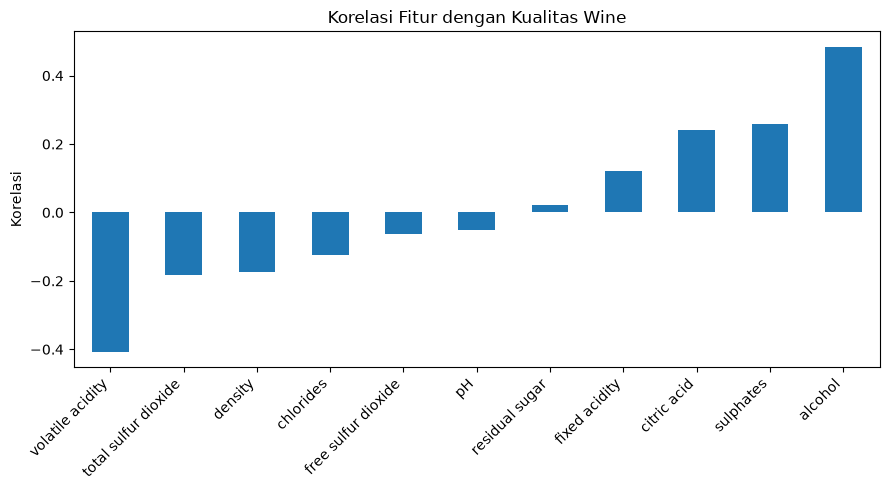

In [3]:
#Melihat hubungan fitur dengan quality
correlations = data.drop(columns=["Id"]).corr()["quality"].drop("quality")
correlations = correlations.sort_values()

plt.figure(figsize=(9, 5))
correlations.plot(kind="bar")
plt.title("Korelasi Fitur dengan Kualitas Wine")
plt.ylabel("Korelasi")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Memilih fitur dan scaling

Agar decision boundary dapat divisualisasikan dalam dua dimensi, kita memilih dua fitur: `alcohol` dan `volatile acidity`. SVM sensitif terhadap skala fitur, sehingga fitur distandardisasi menggunakan `StandardScaler`.

In [4]:
features = ["alcohol", "volatile acidity"]
X_2d = X[features]

X_train, X_test, y_train, y_test = train_test_split(
    X_2d, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data latih:", X_train.shape)
print("Data uji:", X_test.shape)

Data latih: (914, 2)
Data uji: (229, 2)


Linear SVM dan decision boundary

SVM mencari batas keputusan (decision boundary) yang memisahkan kelas. Karena target `quality` memiliki beberapa kelas, model yang digunakan menangani klasifikasi multikelas.

In [5]:
def plot_decision_boundary(model, X_data, y_data, title):
    model.fit(X_data, y_data)

    x_min, x_max = X_data.iloc[:, 0].min() - 0.5, X_data.iloc[:, 0].max() + 0.5
    y_min, y_max = X_data.iloc[:, 1].min() - 0.5, X_data.iloc[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 250),
        np.linspace(y_min, y_max, 250)
    )
    grid = pd.DataFrame(
        np.c_[xx.ravel(), yy.ravel()],
        columns=X_data.columns
    )
    predictions = model.predict(grid).reshape(xx.shape)

    plt.figure(figsize=(8, 6))
    plt.contourf(xx, yy, predictions, alpha=0.25, cmap="viridis")
    scatter = plt.scatter(
        X_data.iloc[:, 0], X_data.iloc[:, 1],
        c=y_data, cmap="viridis", edgecolor="k", s=25
    )
    plt.xlabel(X_data.columns[0])
    plt.ylabel(X_data.columns[1])
    plt.title(title)
    plt.colorbar(scatter, label="Quality")
    plt.show()

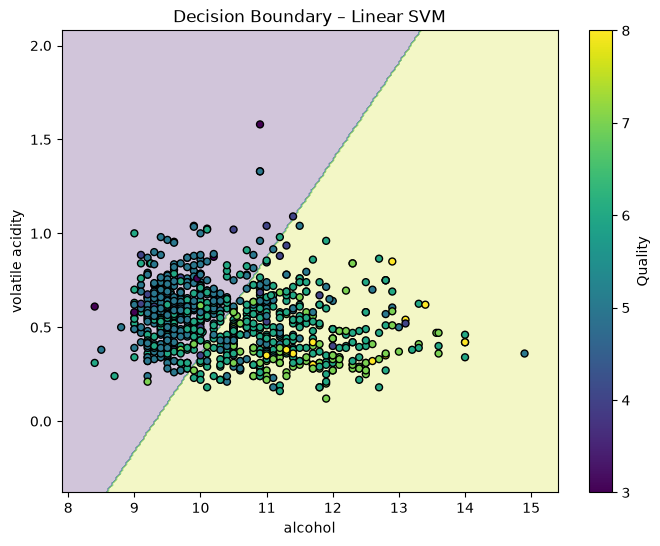

In [6]:
linear_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="linear", C=1))
])

plot_decision_boundary(
    linear_svm, X_train, y_train,
    "Decision Boundary – Linear SVM"
)

Gaussian / RBF Kernel

Kernel RBF dapat membentuk batas keputusan yang lebih fleksibel dibandingkan kernel linear. Parameter `gamma` mengatur jangkauan pengaruh setiap data latih, sedangkan `C` mengatur penalti terhadap kesalahan klasifikasi.

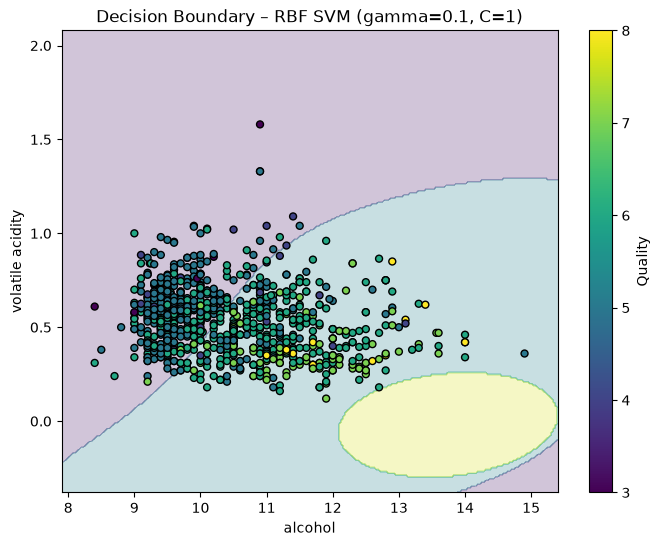

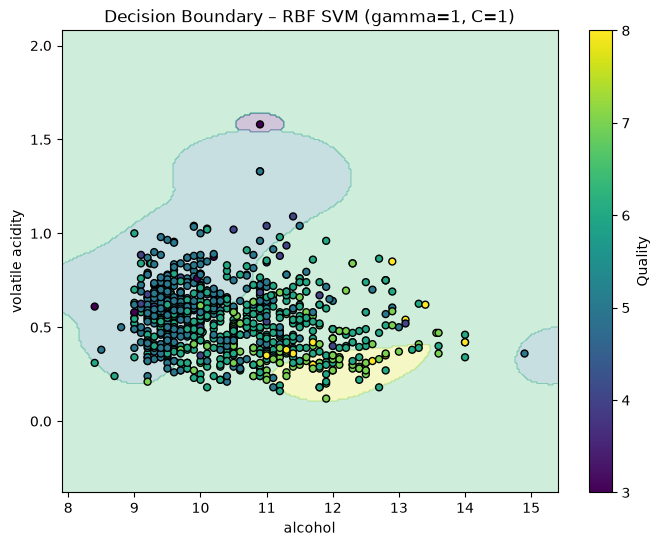

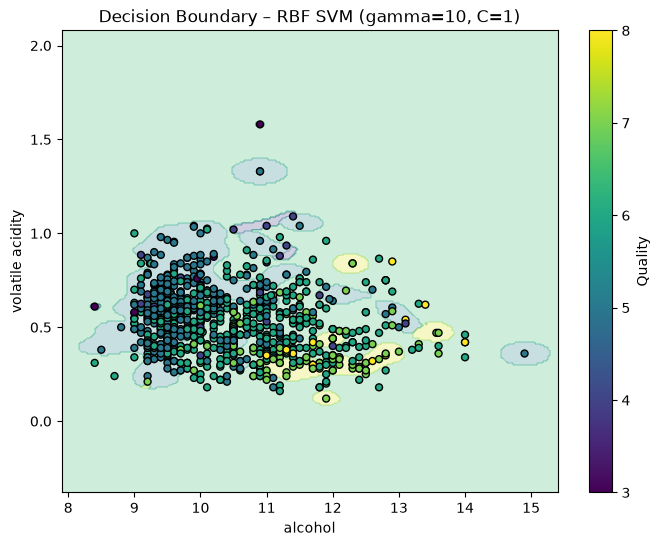

In [7]:
# Membandingkan beberapa nilai gamma
for gamma in [0.1, 1, 10]:
    rbf_svm = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="rbf", C=1, gamma=gamma))
    ])
    plot_decision_boundary(
        rbf_svm, X_train, y_train,
        f"Decision Boundary – RBF SVM (gamma={gamma}, C=1)"
    )

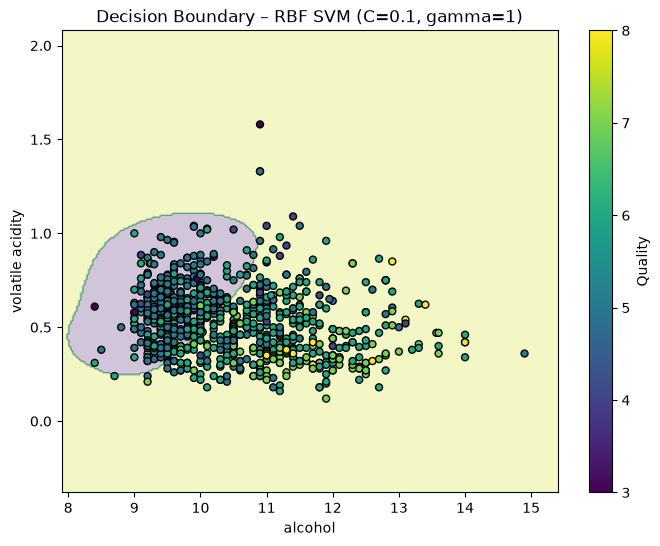

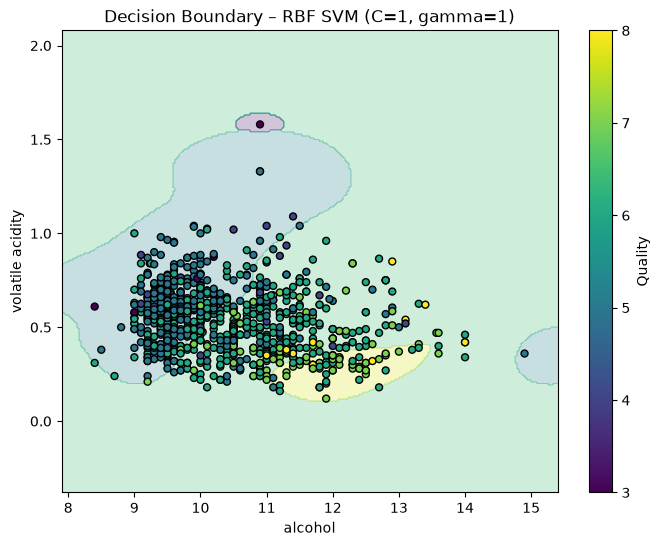

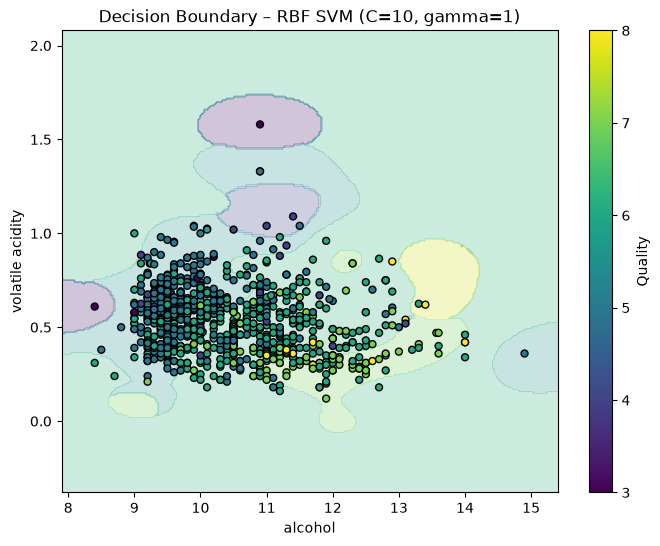

In [8]:
#Membandingkan beberapa nilai C dengan gamma tetap
for c_value in [0.1, 1, 10]:
    rbf_svm = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="rbf", C=c_value, gamma=1))
    ])
    plot_decision_boundary(
        rbf_svm, X_train, y_train,
        f"Decision Boundary – RBF SVM (C={c_value}, gamma=1)"
    )

Evaluasi model

Model dievaluasi menggunakan data uji yang tidak digunakan saat pelatihan. Accuracy memberikan gambaran ketepatan keseluruhan, sedangkan classification report menampilkan precision, recall, dan F1-score untuk setiap kelas.

In [9]:
models = {
    "Linear SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="linear", C=1))
    ]),
    "RBF SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="rbf", C=1, gamma="scale"))
    ])
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions)
    })

    print(name)
    print("Accuracy:", round(accuracy_score(y_test, predictions), 4))
    print(classification_report(y_test, predictions, zero_division=0))

Linear SVM
Accuracy: 0.5983
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00         7
           5       0.64      0.82      0.72        97
           6       0.55      0.62      0.58        92
           7       0.00      0.00      0.00        29
           8       0.00      0.00      0.00         3

    accuracy                           0.60       229
   macro avg       0.20      0.24      0.22       229
weighted avg       0.49      0.60      0.54       229

RBF SVM
Accuracy: 0.6201
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00         7
           5       0.67      0.80      0.73        97
           6       0.58      0.63      0.60        92
           7       0.46      0.21      0.29        29
           8       0.00      0.00      0.00         3

    accuracy            

,Model,Accuracy
0,Linear SVM,0.598253
1,RBF SVM,0.620087


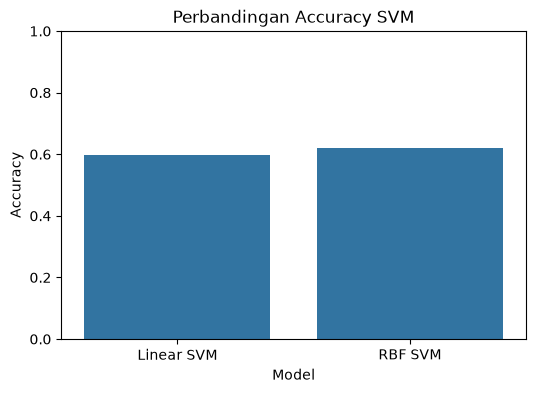

In [10]:
results_df = pd.DataFrame(results)
display(results_df)

plt.figure(figsize=(6, 4))
sns.barplot(data=results_df, x="Model", y="Accuracy")
plt.ylim(0, 1)
plt.title("Perbandingan Accuracy SVM")
plt.show()

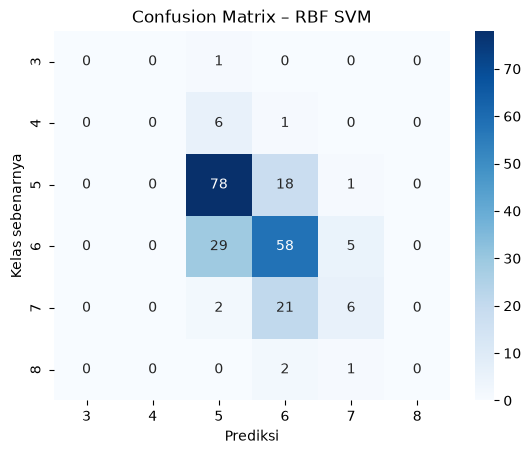

In [11]:
# Confusion matrix untuk model RBF
best_model = models["RBF SVM"]
predictions = best_model.predict(X_test)
labels = sorted(y.unique())

cm = confusion_matrix(y_test, predictions, labels=labels)
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=labels, yticklabels=labels
)
plt.xlabel("Prediksi")
plt.ylabel("Kelas sebenarnya")
plt.title("Confusion Matrix – RBF SVM")
plt.show()

Sumber Dataset

Kaggle - Wine Quality Dataset

Simpan file sebagai `data/WineQT.csv` sebelum menjalankan notebook.